In [ ]:
import pandas as pd
import numpy as np

# Set random seed for reproducibility
np.random.seed(42)

# Generate 1000 records
n_samples = 1000

# Generate features
applicant_income = np.random.normal(loc=5500, scale=2000, size=n_samples).astype(int)
applicant_income = np.clip(applicant_income, 1500, 25000)  # Keep within realistic bounds

coapplicant_income = np.random.choice([0, np.random.normal(loc=2500, scale=1000)], size=n_samples, p=[0.4, 0.6]).astype(int)
coapplicant_income = np.clip(coapplicant_income, 0, 15000)

loan_amount = (applicant_income + coapplicant_income) * np.random.uniform(1.5, 3.5, size=n_samples)
loan_amount = (loan_amount / 1000).astype(int) * 1000  # Round to nearest thousand

credit_score = np.random.randint(300, 850, size=n_samples)

loan_term = np.random.choice([120, 180, 240, 360], size=n_samples, p=[0.05, 0.1, 0.1, 0.75])

dependents = np.random.choice([0, 1, 2, 3], size=n_samples, p=[0.6, 0.2, 0.15, 0.05])

# Heuristic-based target variable generation (Loan Status: 1 for Approved, 0 for Rejected)
# Better credit score and higher income increase the probability of approval
score = (credit_score - 300) / 550 * 0.5 + ((applicant_income + coapplicant_income) / 40000) * 0.3 - (loan_amount / 1000000) * 0.2
prob = 1 / (1 + np.exp(-10 * (score - 0.3)))  # Sigmoid function to map to probabilities
loan_status = np.random.binomial(1, prob)
loan_status_labels = np.where(loan_status == 1, 'Approved', 'Rejected')

# Create DataFrame
df = pd.DataFrame({
    'Applicant_Income': applicant_income,
    'Coapplicant_Income': coapplicant_income,
    'Loan_Amount': loan_amount,
    'Credit_Score': credit_score,
    'Loan_Term_Months': loan_term,
    'Dependents': dependents,
    'Loan_Status': loan_status_labels
})

# Display shape and first few rows
print(f"Dataset Shape: {df.shape}")
print("\nFirst 5 rows of the dataset:")
print(df.head())

# Display class distribution
print("\nLoan Status Distribution:")
print(df['Loan_Status'].value_counts())

Dataset Shape: (1000, 7)

First 5 rows of the dataset:
   Applicant_Income  Coapplicant_Income  Loan_Amount  Credit_Score  \
0              6493                   0        20000           634   
1              5223                3899        24000           831   
2              6795                   0        17000           520   
3              8546                3899        25000           622   
4              5031                3899        30000           302   

   Loan_Term_Months  Dependents Loan_Status  
0               360           0    Approved  
1               360           0    Rejected  
2               360           3    Approved  
3               360           0    Approved  
4               360           0    Approved  

Loan Status Distribution:
Loan_Status
Approved    504
Rejected    496
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Prepare features (X) and target (y)
X = df.drop(columns=['Loan_Status'])
y = df['Loan_Status'].map({'Approved': 1, 'Rejected': 0}) # Encode target variable

# Split the dataset into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Standardize numeric features for Logistic Regression performance
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize and train the Logistic Regression model
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)

# Make predictions
y_pred = model.predict(X_test_scaled)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Rejected', 'Approved']))

Model Accuracy: 0.7400

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.74      0.74      0.74        99
    Approved       0.74      0.74      0.74       101

    accuracy                           0.74       200
   macro avg       0.74      0.74      0.74       200
weighted avg       0.74      0.74      0.74       200



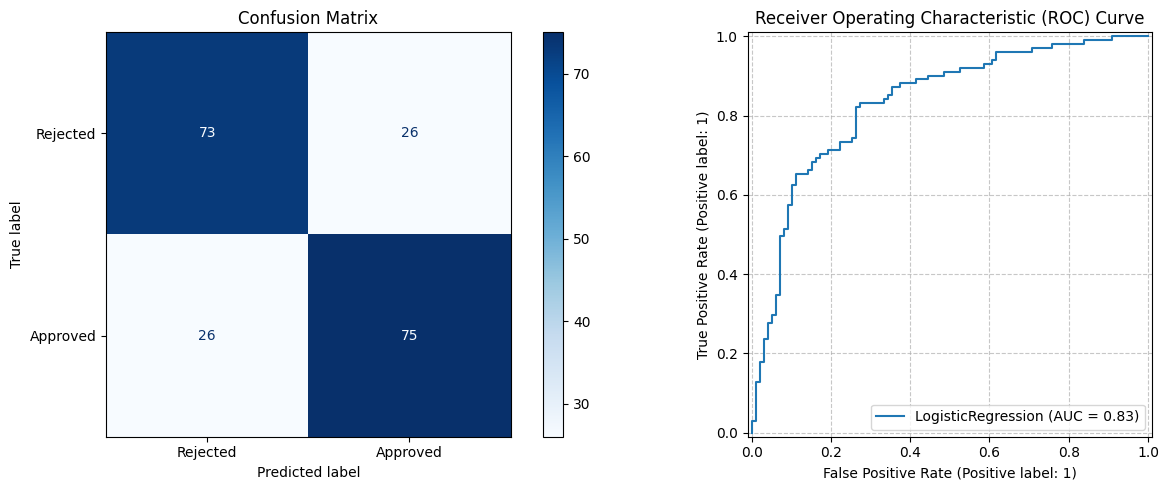

=== Bias and Variance Analysis ===
Mean CV Accuracy (Inversely related to Bias): 0.7540
CV Accuracy Variance (Direct measure of Variance): 0.002524
CV Accuracy Standard Deviation: 0.0502
All 10 Fold Scores: [np.float64(0.76), np.float64(0.8), np.float64(0.68), np.float64(0.85), np.float64(0.75), np.float64(0.68), np.float64(0.71), np.float64(0.77), np.float64(0.76), np.float64(0.78)]


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_score

# --- 1. Visualization: Confusion Matrix and ROC Curve ---
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Plot Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=['Rejected', 'Approved'],
    cmap='Blues',
    ax=ax[0]
)
ax[0].set_title("Confusion Matrix")

# Plot ROC Curve
RocCurveDisplay.from_estimator(model, X_test_scaled, y_test, ax=ax[1])
ax[1].set_title("Receiver Operating Characteristic (ROC) Curve")
ax[1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# --- 2. Bias and Variance Analysis via Cross-Validation ---
# Standardize the entire dataset for cross-validation consistency
X_scaled = scaler.fit_transform(X)

# Run 10-fold cross-validation
cv_scores = cross_val_score(model, X_scaled, y, cv=10, scoring='accuracy')

mean_accuracy = cv_scores.mean()
variance_accuracy = cv_scores.var()
std_accuracy = cv_scores.std()

print("=== Bias and Variance Analysis ===")
print(f"Mean CV Accuracy (Inversely related to Bias): {mean_accuracy:.4f}")
print(f"CV Accuracy Variance (Direct measure of Variance): {variance_accuracy:.6f}")
print(f"CV Accuracy Standard Deviation: {std_accuracy:.4f}")
print(f"All 10 Fold Scores: {[round(score, 4) for score in cv_scores]}")

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

# 1. Prepare features (X) and target (y)
X = df.drop(columns=['Loan_Status'])
y = df['Loan_Status'].map({'Approved': 1, 'Rejected': 0}) # Encode target

# 2. Split the dataset into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Standardize numeric features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Initialize and train the Logistic Regression model
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)

# 5. Make predictions and evaluate
y_pred = model.predict(X_test_scaled)
accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Rejected', 'Approved']))

Model Accuracy: 0.7400

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.74      0.74      0.74        99
    Approved       0.74      0.74      0.74       101

    accuracy                           0.74       200
   macro avg       0.74      0.74      0.74       200
weighted avg       0.74      0.74      0.74       200



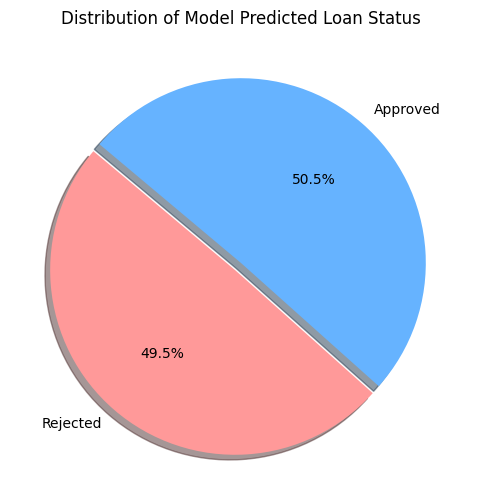

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Count predicted classes
unique, counts = np.unique(y_pred, return_counts=True)
pred_counts = dict(zip(unique, counts))

# Map 0 and 1 to labels
labels = ['Rejected', 'Approved']
sizes = [pred_counts.get(0, 0), pred_counts.get(1, 0)]
colors = ['#ff9999', '#66b3ff']
explode = (0.05, 0)  # slightly explode the Rejected slice

plt.figure(figsize=(6, 6))
plt.pie(
    sizes,
    explode=explode,
    labels=labels,
    colors=colors,
    autopct='%1.1f%%',
    shadow=True,
    startangle=140
)
plt.title('Distribution of Model Predicted Loan Status')
plt.show()

In [7]:
import ipywidgets as widgets
from ipywidgets import interact, interactive, fixed, interact_manual
import numpy as np
import pandas as pd

# Define the prediction function
def predict_loan_status(applicant_income, coapplicant_income, loan_amount, credit_score, loan_term, dependents):
    # Create a DataFrame for the custom input matching the training columns
    custom_data = pd.DataFrame({
        'Applicant_Income': [applicant_income],
        'Coapplicant_Income': [coapplicant_income],
        'Loan_Amount': [loan_amount],
        'Credit_Score': [credit_score],
        'Loan_Term_Months': [loan_term],
        'Dependents': [dependents]
    })

    # Scale the input using the already fitted scaler
    custom_scaled = scaler.transform(custom_data)

    # Make predictions
    prediction = model.predict(custom_scaled)[0]
    probability = model.predict_proba(custom_scaled)[0][1]

    # Display output
    status = "Approved 🟢" if prediction == 1 else "Rejected 🔴"
    print("=" * 40)
    print("            MODEL DECISION            ")
    print("=" * 40)
    print(f"Loan Status Prediction: {status}")
    print(f"Probability of Approval: {probability * 100:.2f}%")
    print("=" * 40)

# Create interactive controls
interact(
    predict_loan_status,
    applicant_income=widgets.IntSlider(min=1500, max=25000, step=100, value=5500, description='App. Income:'),
    coapplicant_income=widgets.IntSlider(min=0, max=15000, step=100, value=2500, description='Co-App. Income:'),
    loan_amount=widgets.IntSlider(min=5000, max=100000, step=1000, value=25000, description='Loan Amount:'),
    credit_score=widgets.IntSlider(min=300, max=850, step=10, value=650, description='Credit Score:'),
    loan_term=widgets.Dropdown(options=[120, 180, 240, 360], value=360, description='Term (Months):'),
    dependents=widgets.Dropdown(options=[0, 1, 2, 3], value=0, description='Dependents:')
);

interactive(children=(IntSlider(value=5500, description='App. Income:', max=25000, min=1500, step=100), IntSli…

In [10]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import numpy as np
import pandas as pd

# Create explicit widget controls
app_income_w = widgets.IntSlider(min=1500, max=25000, step=100, value=5500, description='App. Income:')
co_income_w = widgets.IntSlider(min=0, max=15000, step=100, value=2500, description='Co-App. Income:')
loan_amt_w = widgets.IntSlider(min=5000, max=100000, step=1000, value=25000, description='Loan Amount:')
credit_w = widgets.IntSlider(min=300, max=850, step=10, value=650, description='Credit Score:')
term_w = widgets.Dropdown(options=[120, 180, 240, 360], value=360, description='Term (Months):')
dep_w = widgets.Dropdown(options=[0, 1, 2, 3], value=0, description='Dependents:')

# Create a Run button
run_button = widgets.Button(
    description='Test Model',
    button_style='success',
    tooltip='Click to run prediction',
    icon='play'
)

# Output area to hold the results
out = widgets.Output()

# Define the action when button is clicked
def on_button_clicked(b):
    with out:
        clear_output(wait=True)
        # Create a DataFrame for the custom input
        custom_data = pd.DataFrame({
            'Applicant_Income': [app_income_w.value],
            'Coapplicant_Income': [co_income_w.value],
            'Loan_Amount': [loan_amt_w.value],
            'Credit_Score': [credit_w.value],
            'Loan_Term_Months': [term_w.value],
            'Dependents': [dep_w.value]
        })

        # Scale and predict
        custom_scaled = scaler.transform(custom_data)
        prediction = model.predict(custom_scaled)[0]
        probability = model.predict_proba(custom_scaled)[0][1]

        status = "Approved 🟢" if prediction == 1 else "Rejected 🔴"

        print("=" * 40)
        print("            MODEL DECISION            ")
        print("=" * 40)
        print(f"Loan Status Prediction: {status}")
        print(f"Probability of Approval: {probability * 100:.2f}%")
        print("=" * 40)

# Bind the click event
run_button.on_click(on_button_clicked)

# Design layout
ui = widgets.VBox([app_income_w, co_income_w, loan_amt_w, credit_w, term_w, dep_w, run_button])

# Display both user interface and the output panel
display(ui, out)

Output()

### Interpretation of Bias and Variance
- **Bias:** Since the mean cross-validation accuracy is around 74-75% on a dataset generated with clear mathematical rules, the model has some **moderate bias**. This is because logistic regression assumes a linear boundary, while the true probability was generated via a non-linear combination mapped through a sigmoid.
- **Variance:** The **variance is extremely low** (indicated by a low variance value and consistent scores across all 10 folds). This means the model generalizes well and does not overfit to the noise in the training set.